# **Файл, формат, конвейер: изображения, звук и медиа (Лекция 4)**

*Неделя 4. От файла к медиапайплайну: изображения, звук, ffmpeg*

# Всё — файлы

Посмотрим на пройденное. Неделя 1: рисунок черепашки → **файл** `.svg` → плоттер. Неделя 2: стихи в **файлах** `.txt`, `.csv`, `.json`. Неделя 3: интернет → **файлы** в `data/` и `output/`.

Закономерность очевидна: что бы мы ни делали, в начале и в конце — файл.

На этой неделе мы перестанем делать вид, что файл — это что-то само собой разумеющееся, и посмотрим внутрь. Потому что дальше нас ждут изображения, звук и видео — а там без понимания «что такое файл на самом деле» никуда.

> 💡 **Важная мысль недели:** компьютер не знает, что такое «картинка», «стихотворение» или «песня». Он знает файлы, форматы и преобразования. Всё остальное — договорённости.

## План лекции

| # | Часть | Время |
| - | ----- | ----- |
| 1 | Что такое файл на самом деле: байты и форматы | ~15 мин |
| 2 | Изображения: пиксели, форматы, Pillow, глитч | ~25 мин |
| 3 | Звук: синтез, монтаж (pydub), голос из текста (TTS) | ~30 мин |
| 4 | Видео и ffmpeg: кадры → фильм | ~20 мин |
| 5 | Папка как конвейер и структура проекта | ~20 мин |
| 6 | Blender: у каждой картинки есть код-слой | ~10 мин |
| 7 | Свои модели: компьютерное зрение и GAN | ~10 мин |

# Часть 1. Что такое файл на самом деле

Любой файл — это **последовательность байтов**. Число, число, число, миллионы чисел подряд. И больше ничего.

**Формат** — это договорённость о том, *как читать эти числа*. Одни и те же байты в одной договорённости — портрет, в другой — шум.

**Расширение** (`.jpg`, `.txt`, `.mp3`) — это всего лишь **этикетка на банке**. Она подсказывает, какой договорённостью пользоваться, но не гарантирует содержимого: переименование `poem.txt` в `poem.jpg` не превратит стихи в картинку — только запутает программы.

Как же программы узнают формат на самом деле? Заглядывают в первые байты. Проверим:

In [14]:
# Прочитаем первые байты картинки — не как изображение, а как сырые байты:
with open("images/artists/sol-lewitt/sol_lewitt_connected_ands_1972.jpg", "rb") as f:
    first_bytes = f.read(12)

first_bytes

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.

b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01'

`\xff\xd8\xff` в начале — это **сигнатура** («магические байты») формата JPEG. Настоящий паспорт файла лежит внутри него самого:

| Формат | Первые байты |
| ------ | ------------ |
| JPEG | `FF D8 FF` |
| PNG | `89 50 4E 47` (`.PNG`) |
| GIF | `47 49 46 38` (`GIF8`) |
| PDF | `25 50 44 46` (`%PDF`) |
| ZIP | `50 4B` (`PK`) |

Забавный факт: файлы `.docx` и `.xlsx` начинаются с `PK` — потому что документ Word — это **zip-архив в маскировке**. Переименуйте `.docx` в `.zip` и распакуйте.

### Текст против бинаря

* **Текстовые файлы** (`.txt`, `.csv`, `.json`, `.html`, `.py`, `.svg`) — байты кодируют буквы. Их можно открыть в редакторе и *прочитать глазами*.
* **Бинарные файлы** (`.jpg`, `.mp3`, `.mp4`) — байты кодируют что угодно другое. В редакторе — каша.

С кодировками мы уже сталкивались лично: «Евгений Онегин» на второй неделе не хотел открываться, пока мы не сказали `encoding="cp1251"`. Это была ровно эта история: байты те же — договорённость о чтении другая.

Заметьте: `.svg` из первой недели — картинка, но **текстовая**. Откройте свой плоттерный файл в редакторе — там читаемые команды линий.

# Часть 2. Изображения

## Растр и вектор

Мы уже знаем оба мира, осталось назвать их по имени:

| | **Растр** (`.jpg`, `.png`) | **Вектор** (`.svg`) |
| --- | --- | --- |
| Что хранится | сетка цветных точек — **пикселей** | команды: «линия отсюда сюда» |
| При увеличении | распадается на квадраты | остаётся гладким |
| Родная среда | фотография, экран | плоттер (наша неделя 1!), печать, шрифты |

Каждый пиксель растра — обычно три числа: **R, G, B** (красный, зелёный, синий), каждое от 0 до 255. Картинка 1000×1000 — это три миллиона чисел. Снова: файл — это числа.

## Сжатие: с потерями и без

Три миллиона чисел хранить дорого, поэтому картинки **сжимают** — двумя философиями:

* **Без потерь** (`.png`): распаковал — получил в точности исходные пиксели.
* **С потерями** (`.jpg`): выбрасываем то, что глаз «всё равно не заметит». Файл в разы меньше, но каждая пересохранённая копия чуть хуже предыдущей — как ксерокс ксерокса.

| Формат | Сжатие | Когда использовать |
| ------ | ------ | ------------------ |
| `.png` | без потерь, есть прозрачность | графика, скриншоты, генеративные работы |
| `.jpg` | с потерями | фотографии |
| `.gif` | без потерь, 256 цветов, анимация | пиксельная анимация |
| `.webp` | оба режима | современный веб |
| `.svg` | это вообще текст | всё векторное |

Для Python-работы с растром есть библиотека **Pillow** (историческое имя — PIL). Посмотрим на неё в деле — на знакомом Соле Левитте:

Формат: JPEG
Размер: (1581, 1600)
Режим: RGB


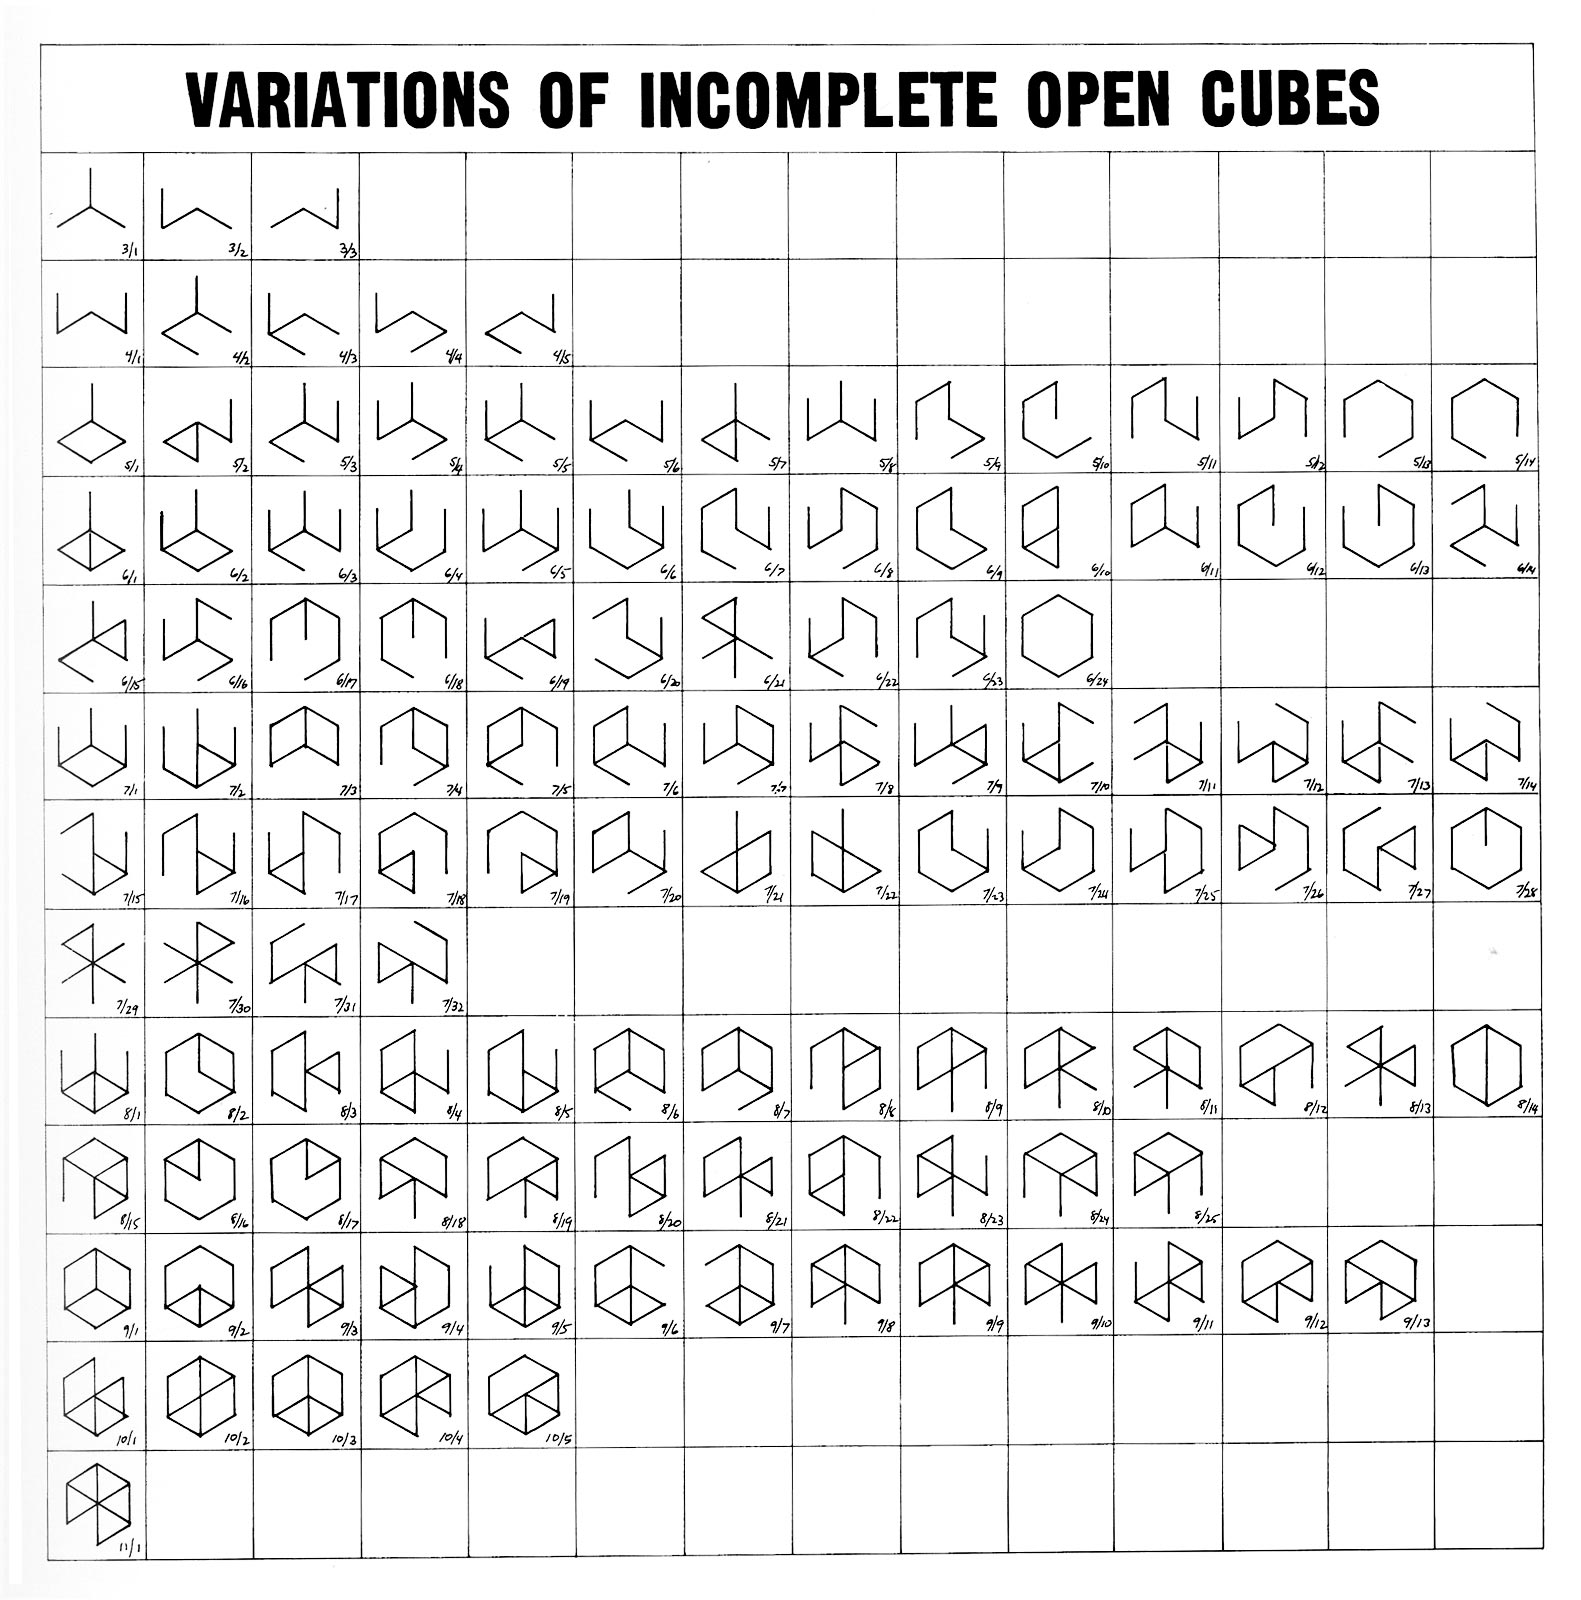

In [3]:
from PIL import Image

img = Image.open("images/artists/sol-lewitt/sol-lewitt_variations-of-incomplete-open-cubes.jpg")

print("Формат:", img.format)
print("Размер:", img.size)       # (ширина, высота) в пикселях
print("Режим:", img.mode)        # RGB — те самые три числа на пиксель

img

In [4]:
# Один пиксель — это правда просто числа:
img.getpixel((100, 100))  # (R, G, B) точки с координатами x=100, y=100

(255, 255, 255)

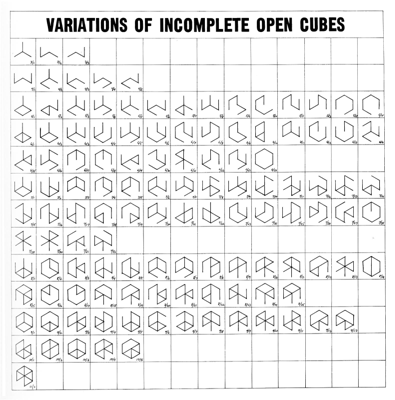

In [5]:
from pathlib import Path

Path("output/lecture4").mkdir(parents=True, exist_ok=True)

# Три классических преобразования — три строчки:
small = img.copy()
small.thumbnail((400, 400))            # уменьшить (пропорции сохраняются)
gray = small.convert("L")              # в оттенки серого: было 3 числа на пиксель, стало 1
rotated = small.rotate(90, expand=True)  # повернуть

small.save("output/lecture4/lewitt_small.png")
gray.save("output/lecture4/lewitt_gray.png")
rotated.save("output/lecture4/lewitt_rotated.png")

gray

## Контекст: глитч и databending

Раз файл — это байты, а формат — договорённость, то **нарушение договорённости — художественный приём**.

* **Rosa Menkman** — теоретик и художница глитча: её «The Glitch Moment(um)» — манифест эстетики ошибки.
* **Cory Arcangel** — от взломанных картриджей Nintendo до «Photoshop Gradient Demonstrations»: инструмент, показанный как инструмент.
* **Databending** — редактирование файла «не тем» инструментом: картинку — звуковым редактором, звук — текстовым.

Сделаем настоящий databending прямо сейчас: испортим несколько байтов внутри JPEG и посмотрим, как договорённость ломается — красиво.

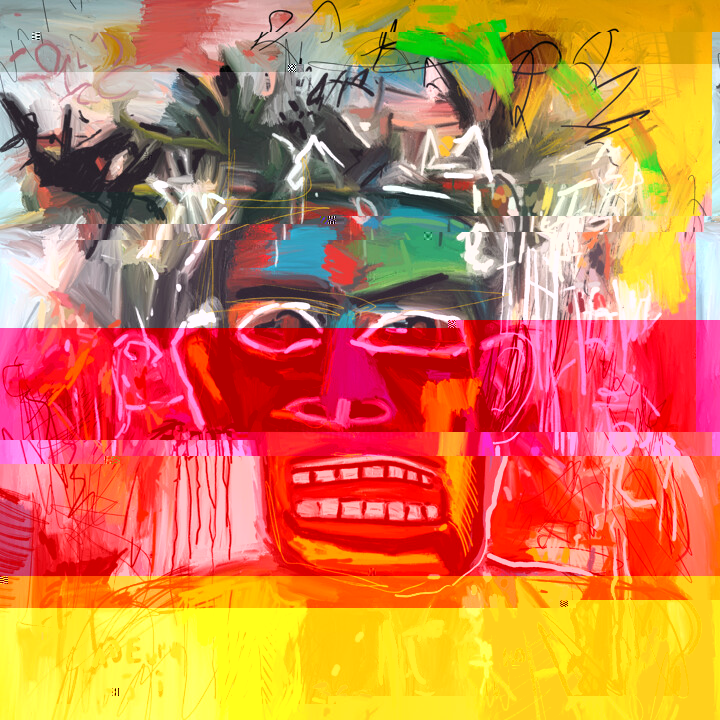

In [18]:
import random
from pathlib import Path

src = Path("images/artists/basquiat/basq-gltich.jpg")
data = bytearray(src.read_bytes())  # bytearray — изменяемые байты

# random.seed(9)  # раскомментируйте, чтобы зафиксировать удачный глитч

for _ in range(25):
    position = random.randrange(6000, len(data))  # начало файла (заголовок) не трогаем
    data[position] = random.randrange(256)        # случайный байт → случайное число

glitch_path = Path("output/lecture4/basquiat_glitch.jpg")
glitch_path.parent.mkdir(parents=True, exist_ok=True)
glitch_path.write_bytes(bytes(data))

from IPython.display import Image as ShowImage
ShowImage(filename=str(glitch_path))


25 испорченных байтов из миллиона — и изображение плывёт. Обратите внимание: мы **ни разу не открывали файл как картинку** — работали с ним как с последовательностью чисел. Это и есть мышление этой недели.

Запустите ячейку ещё раз — глитч будет другой: пока `random.seed` закомментирован, каждый запуск уникален. (Если картинка не открылась вовсе — тоже результат: значит, задели байты заголовка. Просто запустите ещё раз.)

# Часть 3. Звук

## Звук — это тоже числа

Звук в природе — волна давления воздуха. Компьютер записывает её так: тысячи раз в секунду измеряет высоту волны и записывает число. Это называется **дискретизация** (sampling).

* **Частота дискретизации** — сколько измерений в секунду. Стандарт CD: **44 100 раз в секунду**.
* **Амплитуда** — само значение в каждой точке: насколько волна отклонилась.

То есть три минуты звука — это примерно 8 миллионов чисел подряд. Файл. Числа. Опять.

И снова две философии хранения — **вам уже знакомые**:

* `.wav` — без потерь: числа хранятся как есть (философия `.png`);
* `.mp3` — с потерями: выброшено «неслышимое» (философия `.jpg`).

Раз звук — это числа, значит, числа можно **придумать** — и получить звук, которого никогда не было. Синтезируем чистую ноту «ля» (440 колебаний в секунду) стандартной библиотекой, без единой внешней зависимости:

In [ ]:
import math
import struct
import wave

SAMPLE_RATE = 44100   # измерений в секунду
DURATION = 3          # секунды
FREQUENCY = 440       # герц: нота ля первой октавы

with wave.open("output/lecture4/sine_440.wav", "w") as f:
    f.setnchannels(1)                 # моно
    f.setsampwidth(2)                 # 2 байта на число
    f.setframerate(SAMPLE_RATE)
    for i in range(SAMPLE_RATE * DURATION):
        moment = i / SAMPLE_RATE                                # время этой точки, сек
        value = math.sin(2 * math.pi * FREQUENCY * moment)      # волна: число от -1 до 1
        f.writeframesraw(struct.pack("<h", int(value * 32767 * 0.5)))

print("Готово: output/lecture4/sine_440.wav — откройте и послушайте")

In [ ]:
# Послушать прямо в ноутбуке:
from IPython.display import Audio
Audio("output/lecture4/sine_440.wav")

Мы только что *сочинили звук из формулы*. Замените `math.sin` на что-нибудь своё, добавьте вторую частоту, заставьте частоту расти со временем — это уже звуковой синтез.

Отсюда один шаг до **сонификации** — превращения данных в звук. **Ryoji Ikeda** строит на этом целые залы: его «data-verse» и «test pattern» — гигабайты данных, переведённые в звук и стробоскоп. Ваши данные с третьей недели тоже могут звучать.

*(Для работы с микрофоном и звуком в реальном времени существует PyAudio — упоминаем, но в минимум курса не входит.)*

## Монтаж звука: pydub

Синтез — это создание звука с нуля. Но чаще художнику нужен **монтаж**: взять готовые записи, нарезать, склеить, выровнять громкость. Для этого есть библиотека **pydub** (`pip install pydub`).

pydub обращается со звуком как со строкой текста — помните нарезку и склейку со второй недели? Тот же cut-up, только материал — секунды и децибелы:

| Операция | Код |
| -------- | --- |
| первые 3 секунды | `audio[:3000]` — срез, как у списка! |
| склейка встык | `a + b` |
| тише на 8 дБ / громче на 3 дБ | `audio - 8` / `audio + 3` |
| плавный вход / затухание | `.fade_in(500)` / `.fade_out(1500)` (миллисекунды) |
| выровнять громкость | `normalize(audio)` |
| задом наперёд | `.reverse()` |

Для `.wav` больше ничего не нужно; для `.mp3` pydub позовёт на помощь ffmpeg — ещё одна причина его поставить (см. памятку про brew и winget).

In [ ]:
# Монтаж из нашей синтезированной ноты (сначала запустите ячейку с sine_440.wav):
from pydub import AudioSegment
from pydub.effects import normalize

tone = AudioSegment.from_wav("output/lecture4/sine_440.wav")

soft = tone.fade_in(500).fade_out(1500)      # плавный вход и уход
quiet = soft - 8                             # тот же фрагмент, на 8 дБ тише
composition = soft + quiet + soft.reverse()  # склейка: тон · тихое эхо · разворот

composition = normalize(composition)         # выровнять громкость
composition.export("output/lecture4/composition.wav", format="wav")

print(f"Готово: {len(composition) / 1000} секунд — output/lecture4/composition.wav")

In [ ]:
from IPython.display import Audio
Audio("output/lecture4/composition.wav")

## Пайплайн: текст → голос → монтаж

Синтез и монтаж складываются в конвейер со всем, что мы уже умеем. Недостающее звено — **озвучка**: сервисы **Text-to-Speech** (Google Cloud TTS, Yandex SpeechKit, ElevenLabs) — это обычные API из третьей недели: отправляешь текст — получаешь звуковой файл с голосом.

Рецепт (мой проект **AVOID** преподавателя устроен именно так):

```python
# эскиз: понадобится ключ выбранного TTS-сервиса
lines = open("data/poem.txt", encoding="utf-8").read().splitlines()

for i, line in enumerate(lines):
    audio_bytes = tts_api(line)                    # неделя 3: запрос к API
    with open(f"output/voice/line_{i:03d}.mp3", "wb") as f:
        f.write(audio_bytes)                       # response.content → файл

# дальше — папка как конвейер + pydub:
from pydub import AudioSegment
from pydub.effects import normalize

track = AudioSegment.empty()
for path in sorted(Path("output/voice").glob("*.mp3")):
    fragment = AudioSegment.from_file(path)
    track += fragment.fade_in(50).fade_out(120)    # склейка с мягкими швами

normalize(track).export("output/voice_composition.mp3", format="mp3")
```

Проследите за материалом: **текст** (неделя 2) → **API** (неделя 3) → **папка файлов** → **монтаж** (эта неделя). Каждая строка текста становится голосом, голоса — единым треком.

# Часть 4. Видео и ffmpeg

## Видео = кадры + звук + контейнер

Видеофайл — это упаковка, в которой лежат:

* **видеопоток** — последовательность сжатых кадров (тех самых растровых картинок, 24–60 в секунду);
* **аудиопоток** — тот самый звук из чисел;
* **контейнер** — коробка, в которой всё это лежит вместе: `.mp4`, `.mov`, `.mkv` — это форматы *коробки*, а не содержимого.

Способ сжатия потока внутри коробки называется **кодек** (H.264, VP9…). Поэтому бывает, что «mp4 не открывается»: коробка знакомая, а содержимое сжато незнакомым кодеком.

## ffmpeg — универсальный конвертер

**ffmpeg** — программа с интерфейсом из командной строки, которая читает и пишет практически любой медиаформат на свете. Внутри YouTube, VLC и половины видеоиндустрии работает именно она.

Установка на macOS: `brew install ffmpeg`. Дальше — одна команда на любое преобразование:

```bash
# конвертировать формат
ffmpeg -i input.mov output.mp4

# вырезать 5 секунд начиная с 10-й
ffmpeg -i input.mp4 -ss 00:00:10 -t 5 cut.mp4

# вытащить звук из видео
ffmpeg -i input.mp4 -vn soundtrack.mp3

# СОБРАТЬ ВИДЕО ИЗ КАРТИНОК — наш главный приём:
# кадры frame_001.png, frame_002.png, ... → фильм 12 кадров/сек
ffmpeg -framerate 12 -i frame_%03d.png -pix_fmt yuv420p movie.mp4
```

Последняя команда — мост для генеративного искусства: скрипт рисует серию картинок → ffmpeg склеивает их в фильм.

А запускать ffmpeg можно прямо из Python:

```python
import subprocess

subprocess.run(["ffmpeg", "-i", "input.mov", "output.mp4"])
```

> 💡 **Важная мысль:** программы могут звать другие программы. Python здесь — не «исполнитель всего», а **дирижёр**: Pillow готовит кадры, ffmpeg клеит фильм, ваш скрипт управляет.

In [ ]:
# Видео — это серия картинок. Проверим руками: сделаем серию кадров с нуля.
from PIL import Image, ImageDraw
from pathlib import Path

frames_dir = Path("output/lecture4/frames")
frames_dir.mkdir(parents=True, exist_ok=True)

WIDTH, HEIGHT = 640, 360
FRAMES = 48                                  # 4 секунды при 12 кадрах в секунду

for i in range(FRAMES):
    img = Image.new("RGB", (WIDTH, HEIGHT), "black")
    draw = ImageDraw.Draw(img)
    radius = 10 + i * 3                      # круг растёт от кадра к кадру
    x = int(WIDTH * i / FRAMES)              # и движется слева направо
    draw.ellipse(
        (x - radius, HEIGHT//2 - radius, x + radius, HEIGHT//2 + radius),
        outline="white",
        width=3,
    )
    img.save(frames_dir / f"frame_{i:03d}.png")

print(f"Кадров сохранено: {FRAMES} → {frames_dir}")

48 картинок — это уже фильм, просто пока разобранный на кадры. Собирается одной командой ffmpeg (в терминале):

```bash
ffmpeg -framerate 12 -i output/lecture4/frames/frame_%03d.png -pix_fmt yuv420p output/lecture4/first_video.mp4
```

`frame_%03d.png` значит «кадры с номерами из трёх цифр» — `frame_000.png`, `frame_001.png`, … — ffmpeg подхватит их по порядку.

> 💡 Это главный генеративный приём недели: **Pillow рисует кадры циклом — ffmpeg склеивает их в видео.** Замените круг на свой паттерн из первой недели — и получите анимацию собственной генеративной графики.

# Часть 5. Папка как конвейер

До сих пор мы обрабатывали файлы по одному. Но настоящая сила скрипта — **серийность**: обработать сто файлов так же легко, как один. Художник, умеющий это, мыслит сериями, а не кадрами.

Рецепт: пройти по папке → преобразовать каждый файл → сложить результат в `output/`.

In [ ]:
from pathlib import Path
from PIL import Image

source_dir = Path("images/artists/sol-lewitt")
target_dir = Path("output/lecture4/thumbs")
target_dir.mkdir(parents=True, exist_ok=True)

for path in sorted(source_dir.glob("*.jp*g")):   # все .jpg и .jpeg в папке
    img = Image.open(path).convert("L")          # каждую — в оттенки серого
    img.thumbnail((400, 400))                    # каждую — уменьшить
    img.save(target_dir / f"{path.stem}_thumb.png")
    print("готово:", path.name)

Четыре файла или четыре тысячи — скрипт один и тот же. Это и есть **медиапайплайн**: `input → преобразование → output`, где вход и выход — папки, а не отдельные файлы.

## Структура проекта

Когда файлов и скриптов становится много, проект держится на договорённости о папках. Наш стандарт до конца курса:

```
my_project/
├── data/             ← сырьё (скачанное, собранное) — не трогаем
├── input/            ← то, что подаём на вход конвейеру
├── output/           ← результаты — можно удалять и пересоздавать
├── scripts/          ← наши .py-файлы
├── README.md         ← что это, что на входе, как запустить, что на выходе
└── requirements.txt  ← список библиотек (pip install -r requirements.txt)
```

`README.md` и `requirements.txt` — это письмо будущему себе: через месяц вы откроете проект и за минуту вспомните, как он работает.

## Git: фиксируем стадии

С первой недели мы знаем `git init / add / commit`. На этой неделе — привычка коммитить **осмысленные стадии**, а не «всё подряд в конце»:

1. `setup` — структура папок и пустые скрипты;
2. `first output` — конвейер впервые дал результат;
3. `cleanup` — навели порядок в путях и названиях;
4. `рабочая версия` — то, что не стыдно показать.

Каждый коммит — сохранённая точка, к которой можно вернуться, когда «всё сломалось» (оно сломается — это нормально).

# Часть 6. Blender: у каждой картинки есть код-слой

**Blender** — свободная программа для 3D: моделирование, свет, камера, рендер, анимация. На практике этой недели мы руками пощупаем сцену: куб, свет, камеру.

Зачем он в лекции про файлы? Из-за одной детали: в Blender есть **Python Console**. Вся программа — кнопки поверх Python-процедур. Каждый клик мышкой можно записать строчкой кода:

```python
# выполняется внутри Blender (Scripting → Python Console)
import bpy

for x in range(10):
    for y in range(10):
        bpy.ops.mesh.primitive_cube_add(
            size=0.8,
            location=(x, y, 0),
        )
```

Сто кубов сеткой — одним циклом `for`, тем же самым, что рисовал паттерны черепашкой на первой неделе. Разница только в среде.

Blender у нас — **не обязательный трек**, а демонстрация принципа:

> 💡 **Важная мысль:** любая серьёзная визуальная среда — Blender, Photoshop, After Effects — имеет процедурный слой. GUI — это кнопки поверх кода. Кто умеет писать код, тот умеет нажимать тысячу кнопок одной строкой.

# Часть 7. Свои модели: компьютерное зрение и GAN

Весь курс мы пользуемся готовыми инструментами: Pillow читает пиксели, ffmpeg клеит кадры. Следующая ступень — модели, которые **учатся на ваших данных**.

Два понятия на карту мира:

* **Компьютерное зрение (computer vision)** — программы, которые не просто читают пиксели, а «видят»: находят на фото людей, машины, окна, стулья. Готовые модели детекции объектов (например, YOLO) делают это несколькими строками кода: на вход — фото, на выход — список, что найдено и где.
* **GAN, генеративно-состязательная сеть** — модель из двух половин: **генератор** рисует, **дискриминатор** критикует. Соревнуясь друг с другом, они учатся создавать изображения, похожие на те, что видели при обучении. **DCGAN** — классическая архитектура 2015 года: обучается на обычном ноутбуке или в бесплатном Google Colab.

## Кейс: «Внеобъектная фотография» — 40 000 снимков, из которых всё исчезло

Проект вашего преподавателя — все инструменты этой недели в одной работе, и у каждого шага есть имя:

1. **Датасет:** 40 000 собственных фотографий — папка как материал (Часть 5).
2. **Компьютерное зрение — YOLO:** детектор объектов проходит по всем снимкам и находит людей, машины, предметы — всё найденное удаляется из кадров. Остаются «опустевшие» сцены: свет, фактуры, пустые углы.
3. **Обучение — DCGAN:** на этих сценах обучается модель — эпоха за эпохой она учится «фотографировать» мир, из которого всё исчезло.
4. **Переходы — интерполяция:** между сгенерированными кадрами модель строит плавные промежуточные состояния (интерполяция в латентном пространстве) — получаются тысячи кадров непрерывного перетекания.
5. **Апскейл — Real-ESRGAN:** ещё одна нейросеть увеличивает разрешение каждого кадра.
6. **Видео — ffmpeg:** 20 000 кадров склеиваются в фильм — ровно тем приёмом, что мы разобрали в Части 4.

<table style="width:100%; border-collapse:collapse;">
<tr>
<td style="width:50%; padding:6px; vertical-align:top;">
    <img src="images/artists/viktor-kertanov/dcgan_training_epochs.gif" style="max-width:100%;" alt="Сетка образцов DCGAN, меняющаяся от эпохи к эпохе">
</td>
<td style="width:50%; padding:6px; vertical-align:top;">
    <img src="images/artists/viktor-kertanov/dcgan_samples_grid.gif" style="max-width:100%;" alt="Сетка сгенерированных образцов обученной модели">
</td>
</tr>
</table>

*Слева: модель учится — сетка образцов меняется от эпохи к эпохе (в заголовке кадра — номер эпохи). Справа: образцы обученной модели.*

Финал — фрагмент готовой работы:

<video src="media/lecture4_non_object_excerpt.mp4" controls loop width="640"></video>

> 💡 Присмотритесь: это всё та же формула недели — **папка → преобразование → папка**. Каждая нейросеть здесь — просто ещё одно преобразование в конвейере. Разница в том, что модель обучена на собственном архиве, — и поэтому результат не похож ни на чей другой.

Это необязательный трек: на субботней студии желающие смогут посмотреть код проекта и попробовать готовую локальную модель.


# Итог

💡 **Важная мысль недели:** компьютер работает с файлами, файл — это байты, формат — договорённость о их чтении, а конвертация и конвейер — способ превращать одно в другое. Картинка, звук и видео перестали быть «волшебными объектами» — это числа, к которым у вас есть доступ.

**К концу недели вы умеете:**

* объяснить, что такое файл, формат, расширение и кодировка — и чем они отличаются;
* открывать, преобразовывать и сохранять изображения через Pillow;
* объяснить (и услышать), что звук — это числа; синтезировать простой тон;
* конвертировать и собирать медиа через ffmpeg, в том числе картинки → видео;
* монтировать звук: нарезка, склейка, fade in/out, громкость (pydub) — в том числе голоса, полученные из текста через TTS-API;
* «прочитать» конвейер AI-проекта: YOLO → DCGAN → интерполяция → Real-ESRGAN → ffmpeg;
* обработать целую папку файлов одним скриптом;
* оформить проект: `data/ input/ output/ scripts/ README.md requirements.txt` + осмысленные коммиты.

## Словарь недели

| Термин | Значение |
| ------ | -------- |
| **байт** | минимальная порция данных; файл — последовательность байтов |
| **формат** | договорённость о том, как читать байты файла |
| **расширение** | этикетка в имени файла (`.jpg`); подсказка, а не гарантия |
| **сигнатура** | «магические байты» в начале файла — его настоящий паспорт |
| **кодировка** | договорённость о чтении текста (utf-8, cp1251) |
| **растр** | изображение как сетка пикселей (`.jpg`, `.png`) |
| **вектор** | изображение как команды рисования (`.svg`) |
| **пиксель, RGB** | точка растра; три числа: красный, зелёный, синий (0–255) |
| **сжатие без потерь / с потерями** | png/wav против jpg/mp3: точность против размера |
| **Pillow (PIL)** | библиотека Python для работы с растром |
| **дискретизация** | запись волны числами N раз в секунду (44 100 — стандарт CD) |
| **сонификация** | превращение данных в звук |
| **pydub** | монтаж аудио: нарезка, склейка, fade, громкость |
| **TTS (text-to-speech)** | API-сервис озвучки: текст на входе — файл с голосом на выходе |
| **fade in / fade out** | плавное нарастание / затухание звука |
| **кодек** | способ сжатия видео/аудио потока (H.264…) |
| **контейнер** | «коробка» медиафайла: `.mp4`, `.mov`, `.mkv` |
| **ffmpeg** | универсальный конвертер медиа из командной строки |
| **subprocess** | способ запускать другие программы из Python |
| **pipeline / конвейер** | папка на входе → преобразование → папка на выходе |
| **requirements.txt** | список зависимостей проекта |
| **bpy** | Python-интерфейс Blender: GUI как код |
| **компьютерное зрение** | модели, которые «видят»: находят объекты на изображениях |
| **детекция объектов** | на вход фото — на выход список: что найдено и где (например, YOLO) |
| **GAN / DCGAN** | генеративно-состязательная сеть: генератор рисует, дискриминатор критикует |
| **датасет** | коллекция данных, на которой учится модель |
| **эпоха** | один полный проход обучения по всему датасету |
| **интерполяция** | плавный переход между двумя состояниями; у GAN — между двумя образами |
| **Real-ESRGAN** | нейросеть-апскейлер: увеличивает разрешение изображения |